<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/4_1_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!apt-get -q -y install libopencv-dev

Reading package lists...
Building dependency tree...
Reading state information...
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [15]:
%%writefile prewitt.cpp
#include <opencv2/opencv.hpp>
#include <iostream>

using namespace cv;
using namespace std;

int main(int argc, char** argv) {

    if (argc != 2) {
        cout << "Kullanım: ./prewitt <test>" << endl;
        return -1;
    }


    Mat image = imread(argv[1], IMREAD_GRAYSCALE);
    if (image.empty()) {
        cout << "Görüntü okunamadı! Lütfen dosya adını kontrol edin." << endl;
        return -1;
    }


    float prewitt_x_data[9] = {-1, 0, 1,
                               -1, 0, 1,
                               -1, 0, 1};
    Mat prewitt_x_kernel = Mat(3, 3, CV_32F, prewitt_x_data);


    Mat filtered_image;
    // Negatif değerleri korumak için derinliği CV_32F yaptıkk
    filter2D(image, filtered_image, CV_32F, prewitt_x_kernel);

    // Görüntülenebilmesi için mutlak değerini aldık ve 8-bit formata çevirdik
    Mat filtered_image_abs;
    convertScaleAbs(filtered_image, filtered_image_abs);

    // 4. Sonucu kaydet (Colab'da imshow kullanılamadığı için kaydediyoruz)
    imwrite("prewitt_x_sonuc.jpg", filtered_image_abs);

    cout << "İşlem başarılı! Sonuç 'prewitt_x_sonuc.jpg' olarak kaydedildi." << endl;

    return 0;
}

Overwriting prewitt.cpp


In [16]:
# Kodu OpenCV kütüphanelerini bağladık
!g++ prewitt.cpp -o prewitt_program `pkg-config --cflags --libs opencv4`

# Programı çalıştır
!./prewitt_program "Orijinal Görüntü"

İşlem başarılı! Sonuç 'prewitt_x_sonuc.jpg' olarak kaydedildi.


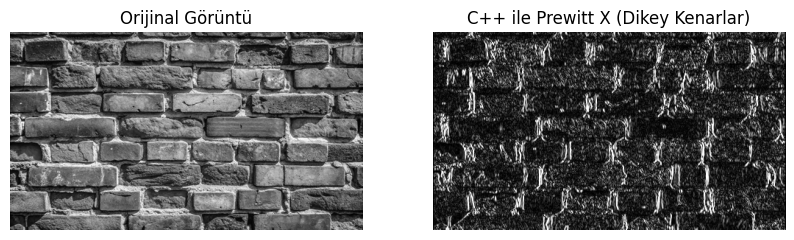

In [17]:
import cv2
import matplotlib.pyplot as plt

# Orijinal ve filtrelenmiş görüntüleri okuttuk
orijinal = cv2.imread('Orijinal Görüntü', cv2.IMREAD_GRAYSCALE)
sonuc = cv2.imread('prewitt_x_sonuc.jpg', cv2.IMREAD_GRAYSCALE)

# Ekrana bastık (bu algortima ile birlikte dikey kenarlar daha belirgin hale geldi)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(orijinal, cmap='gray')
plt.title('Orijinal Görüntü')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sonuc, cmap='gray')
plt.title('C++ ile Prewitt X (Dikey Kenarlar)')
plt.axis('off')

plt.show()